## We wire the `Nodes`(Link)

---

### Extract the created NumPy data:

In [12]:
import numpy as np

In [13]:
node_labels = np.load('../01-Dataset/node_labels.npy')
node_metrics = np.load('../01-Dataset/node_metrics.npy')

### Using cosine similarity:

In [3]:
# %pip install networkx

In [14]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_mat = cosine_similarity(node_metrics) # Calculate Behavioral 'Homophily'
# print(type(similarity_mat))


### Add nodes first:

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph()

num_nodes = len(node_labels)
# print(num_nodes)
similarity_threshold = 0.90 # A hardcoded threshold for now

# Adding nodes to the graph
for i in range(0, num_nodes):
    G.add_node(i, label=node_labels[i])

### Adding edges:

In [10]:
# Wiring the nodes IFF threshold > 90%

for i in range(num_nodes):
    for j in range(i + 1, num_nodes): # No self loops
        
        if similarity_mat[i, j] >= similarity_threshold:
            G.add_edge(i, j)

### Plot the network:

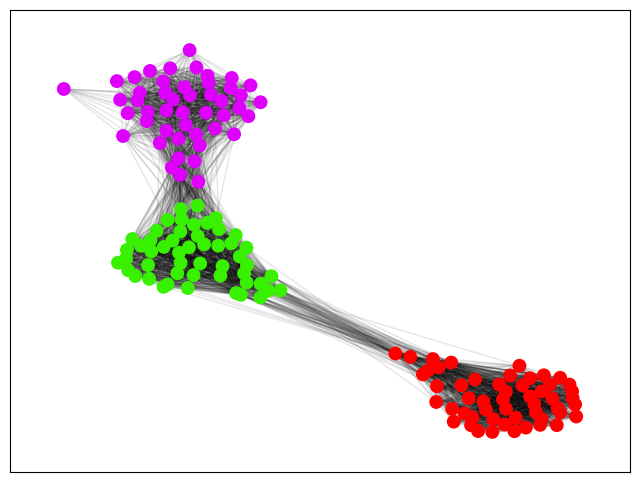

In [11]:

plt.figure(figsize=(8, 6))

pos = nx.spring_layout(G, seed=42)  # The engine which pulls the connected node together

color = [
    "#ff0000" if label == 0 else "#de00fc" if label == 1 else "#38F100" for label in node_labels
]

nx.draw_networkx_nodes(G, pos, node_color=color, node_size=80)
nx.draw_networkx_edges(G, pos, alpha=0.1)

plt.show()